# Stress test: усиленная feature-noise атака

Парное сравнение FedAvg на MNIST без атаки и при намеренно жёстком отравлении признаков: **80% клиентов** добавляют гауссов шум ко **всем** своим локальным изображениям. Метки остаются правильными. Это стресс-тест инфраструктуры, а не реалистичная оценка типичной угрозы.

## 1. Конфигурация

In [1]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import Markdown, display
except ImportError:
    Markdown = str
    def display(value):
        return value

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pyproject.toml').exists():
    PROJECT_ROOT = next(path for path in [PROJECT_ROOT, *PROJECT_ROOT.parents] if (path / 'pyproject.toml').exists())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from fl_benchmark.attacks.label_flip import build_label_flip_plan, make_client_dataset
from fl_benchmark.config import load_config
from fl_benchmark.datasets.loader import load_datasets
from fl_benchmark.datasets.partitioning import create_partitions, get_targets
from fl_benchmark.datasets.statistics import compute_partition_statistics
from fl_benchmark.task import run_local_simulation

NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / 'notebooks' / 'results'
REPORT_PICS_DIR = PROJECT_ROOT / 'practice_report' / 'pics'
NOTEBOOK_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_PICS_DIR.mkdir(parents=True, exist_ok=True)

base_config = load_config(PROJECT_ROOT / 'configs' / 'mnist_strong_feature_noise.toml')
clean_config = replace(
    base_config,
    name='mnist-strong-feature-noise-clean-control',
    attack=replace(base_config.attack, enabled=False, type='none', malicious_fraction=0.0, poison_fraction=0.0),
    tracking=replace(base_config.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name='mnist-strong-feature-noise-clean-control'),
    source_path=None,
)
attack_config = replace(
    base_config,
    name='mnist-strong-feature-noise-attack',
    tracking=replace(base_config.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name='mnist-strong-feature-noise-attack'),
    source_path=None,
)
display(pd.DataFrame([
    ('Датасет / модель / стратегия', f'{base_config.dataset.name} / {base_config.model.name} / {base_config.strategy.name}'),
    ('Клиенты / раунды', f'{base_config.partition.num_clients} / {base_config.federation.num_rounds}'),
    ('Non-IID режим', f'{base_config.partition.type}, alpha={base_config.partition.alpha}'),
    ('Доля вредоносных клиентов', f'{attack_config.attack.malicious_fraction:.0%}'),
    ('Доля зашумлённых примеров у них', f'{attack_config.attack.poison_fraction:.0%}'),
    ('Стандартное отклонение шума', f"{attack_config.attack.noise_std} (нормализованное пространство)"),
], columns=['Параметр', 'Значение']))

,Параметр,Значение
0,Датасет / модель / стратегия,mnist / mnist-cnn / fedavg
1,Клиенты / раунды,10 / 5
2,Non-IID режим,"dirichlet, alpha=0.5"
3,Доля вредоносных клиентов,80%
4,Доля зашумлённых примеров у них,100%
5,Стандартное отклонение шума,3.0 (нормализованное пространство)


## 2. Non-IID-разбиение и масштаб атаки

,client_id,роль,num_examples,entropy,js_divergence,зашумлено примеров
0,0,вредоносный,5669,2.763039,0.149579,5669
1,1,честный,6558,1.947109,0.340865,0
2,2,вредоносный,5193,2.805736,0.126478,5193
3,3,вредоносный,9858,2.701288,0.161481,9858
4,4,вредоносный,4116,2.853040,0.141588,4116
5,5,честный,4606,2.929246,0.102907,0
6,6,вредоносный,10756,2.579138,0.205664,10756
7,7,вредоносный,3576,2.136336,0.290717,3576
8,8,вредоносный,5684,2.637645,0.195135,5684
9,9,вредоносный,3984,2.290201,0.263737,3984


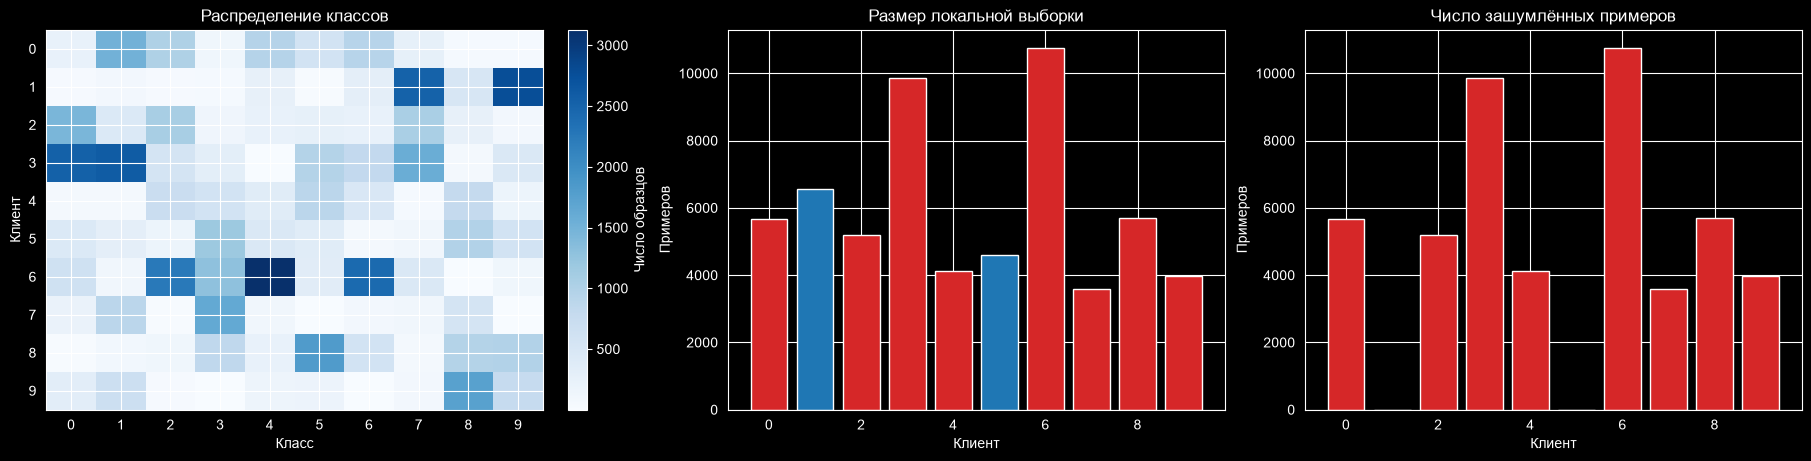

In [2]:
bundle = load_datasets(attack_config.dataset)
targets = get_targets(bundle.train)
partitions = create_partitions(bundle.train, attack_config.partition)
partition_stats = compute_partition_statistics(targets, partitions, attack_config.model.num_classes)
attack_plan = build_label_flip_plan(targets, partitions, attack_config.attack)

stats = partition_stats.statistics.copy().sort_values('client_id')
stats['роль'] = np.where(stats['client_id'].isin(attack_plan.malicious_clients), 'вредоносный', 'честный')
stats['зашумлено примеров'] = [len(attack_plan.poisoned_indices.get(client_id, ())) for client_id in stats['client_id']]
display(stats[['client_id', 'роль', 'num_examples', 'entropy', 'js_divergence', 'зашумлено примеров']])

matrix = partition_stats.matrix.set_index('client_id')
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), constrained_layout=True)
image = axes[0].imshow(matrix.to_numpy(), aspect='auto', cmap='Blues')
axes[0].set(title='Распределение классов', xlabel='Класс', ylabel='Клиент', xticks=range(10), yticks=range(len(matrix)))
fig.colorbar(image, ax=axes[0], label='Число образцов')
colors = np.where(stats['роль'].eq('вредоносный'), 'tab:red', 'tab:blue')
axes[1].bar(stats['client_id'], stats['num_examples'], color=colors)
axes[1].set(title='Размер локальной выборки', xlabel='Клиент', ylabel='Примеров')
axes[2].bar(stats['client_id'], stats['зашумлено примеров'], color=colors)
axes[2].set(title='Число зашумлённых примеров', xlabel='Клиент', ylabel='Примеров')
fig.savefig(REPORT_PICS_DIR / '05_strong_feature_noise_comparison_attack_scenario.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Реализованный план атаки

Шум накладывается только в локальной обёртке датасета вредоносного клиента; исходный MNIST на диске не меняется. Для визуализации ниже значения обратимо переводятся из нормализованного пространства в диапазон пикселей [0, 1].

{
  "enabled": true,
  "type": "feature_noise",
  "seed": 42,
  "malicious_fraction": 0.8,
  "poison_fraction": 1.0,
  "noise_std": 3.0,
  "source_label": 0,
  "target_label": 1,
  "label_flips": [],
  "malicious_clients": [
    0,
    2,
    3,
    4,
    6,
    7,
    8,
    9
  ],
  "num_malicious_clients": 8,
  "poisoned_examples_per_client": {
    "0": 5669,
    "2": 5193,
    "3": 9858,
    "4": 4116,
    "6": 10756,
    "7": 3576,
    "8": 5684,
    "9": 3984
  },
  "total_poisoned_examples": 48836,
  "poisoned_examples_by_flip": {}
}


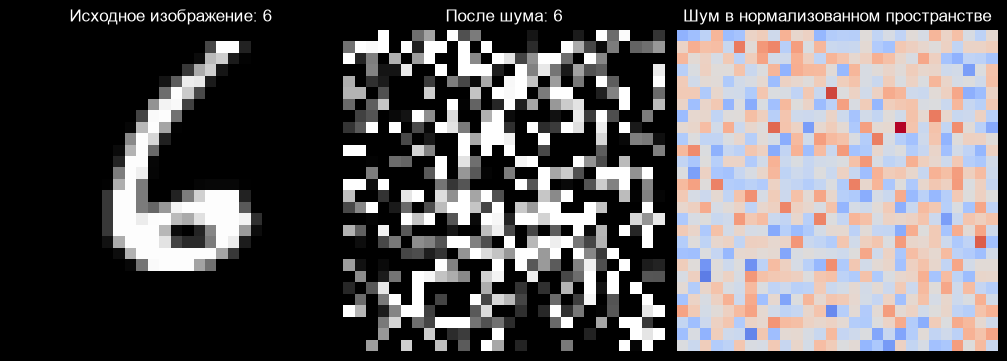

In [3]:
manifest = attack_plan.manifest()
print(json.dumps({key: value for key, value in manifest.items() if key != 'poisoned_indices'}, ensure_ascii=False, indent=2))

client_id = attack_plan.malicious_clients[0]
local_dataset = make_client_dataset(bundle.train, partitions[client_id], attack_plan, client_id)
local_index = next(i for i, global_index in enumerate(partitions[client_id]) if global_index in attack_plan.poisoned_indices[client_id])
original, label = bundle.train[partitions[client_id][local_index]]
noisy, noisy_label = local_dataset[local_index]
to_pixels = lambda tensor: (tensor * 0.3081 + 0.1307).clamp(0, 1)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), constrained_layout=True)
for axis, image, title, cmap in [
    (axes[0], to_pixels(original), f'Исходное изображение: {label}', 'gray'),
    (axes[1], to_pixels(noisy), f'После шума: {noisy_label}', 'gray'),
    (axes[2], (noisy - original).squeeze(), 'Шум в нормализованном пространстве', 'coolwarm'),
]:
    if cmap == 'coolwarm':
        limit = float(image.abs().max())
        axis.imshow(image, cmap=cmap, vmin=-limit, vmax=limit)
    else:
        axis.imshow(image.squeeze(), cmap=cmap, vmin=0, vmax=1)
    axis.set_title(title); axis.axis('off')
fig.savefig(REPORT_PICS_DIR / '05_strong_feature_noise_comparison_poisoned_examples.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Полный парный запуск

На CPU два запуска MNIST могут занять несколько минут. Контроль и атака используют одинаковые разбиение, модель, стратегию и seed; отличаются только параметрами атаки.

In [4]:
RUN_FULL_EXPERIMENTS = True

def latest_result(prefix):
    matches = sorted(NOTEBOOK_RESULTS_DIR.glob(f'{prefix}-*'), key=lambda path: path.stat().st_mtime)
    if not matches:
        raise FileNotFoundError(f'Не найдены результаты {prefix!r}')
    return matches[-1]

if RUN_FULL_EXPERIMENTS:
    clean_output_dir = run_local_simulation(clean_config)
    attack_output_dir = run_local_simulation(attack_config)
else:
    clean_output_dir = latest_result('mnist-strong-feature-noise-clean-control')
    attack_output_dir = latest_result('mnist-strong-feature-noise-attack')
print(f'Контроль: {clean_output_dir}\nАтака: {attack_output_dir}')

Контроль: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-strong-feature-noise-clean-control-20261125-151431-56d79300
Атака: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-strong-feature-noise-attack-20261125-151712-07b8cfc8


## 5. Сравнение глобальных и поклассовых метрик

,Метрика,Контроль,Усиленная атака,Разность
0,Итоговая accuracy,0.973100,0.942500,-0.030600
1,Итоговый loss,0.085004,0.247122,0.162118
2,Macro F1,0.972849,0.941337,-0.031512
3,Отравлённых примеров,0.000000,48836.000000,48836.000000


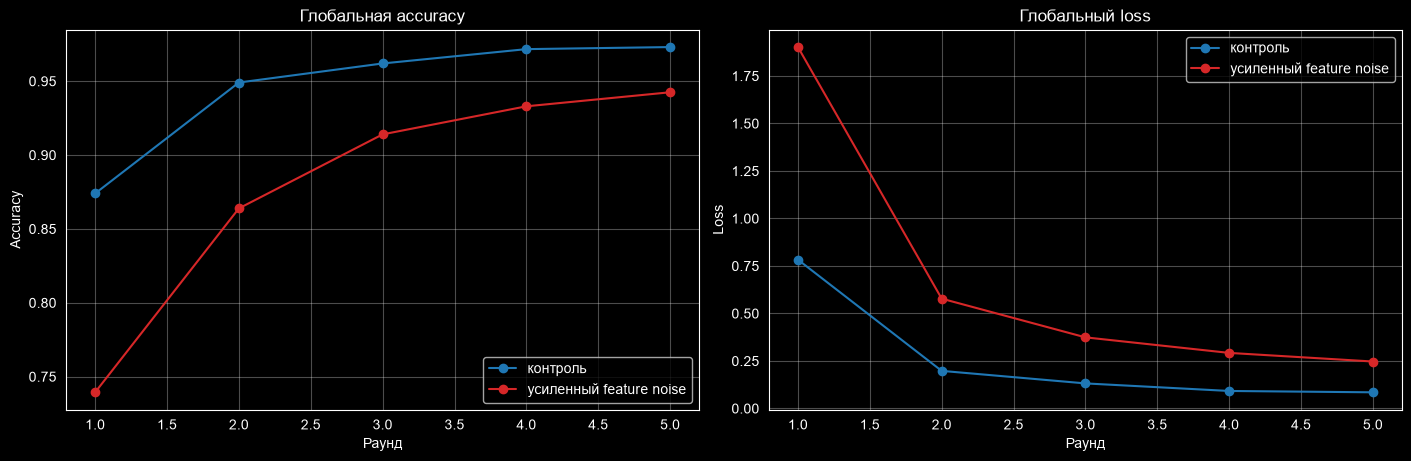

,class_id,support,accuracy_control,accuracy_attack,accuracy_delta_pp,loss_control,loss_attack,loss_delta
0,0,980,0.9959,0.9888,-0.7143,0.0271,0.0670,0.0399
1,1,1135,0.9956,0.9868,-0.8811,0.0229,0.0901,0.0672
2,2,1032,0.9777,0.9583,-1.9380,0.0542,0.1547,0.1006
3,3,1010,0.9782,0.9356,-4.2574,0.0719,0.2610,0.1891
4,4,982,0.9796,0.9593,-2.0367,0.0609,0.1932,0.1323
5,5,892,0.9798,0.9552,-2.4664,0.0709,0.2182,0.1473
6,6,958,0.9864,0.9760,-1.0438,0.0343,0.0820,0.0477
7,7,1028,0.9630,0.9416,-2.1401,0.0942,0.1958,0.1017
8,8,974,0.9148,0.8162,-9.8563,0.2742,0.7690,0.4948
9,9,1009,0.9574,0.9019,-5.5500,0.1478,0.4626,0.3148


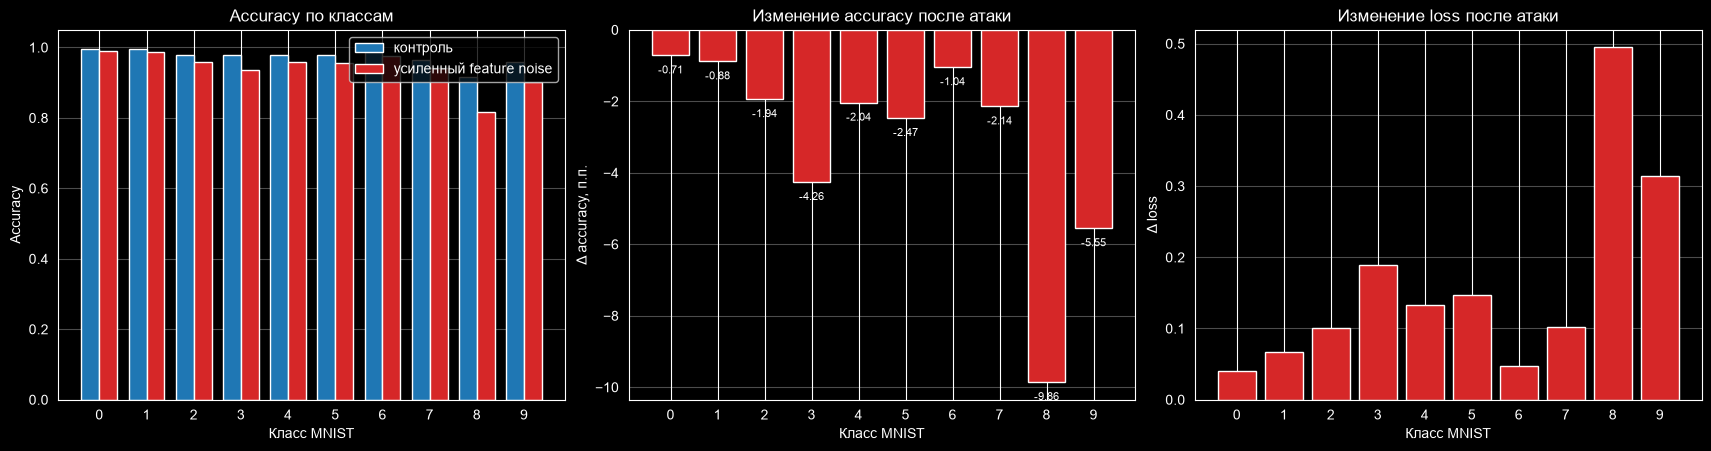

In [5]:
def load_run(output_dir):
    return {
        'summary': json.loads((output_dir / 'summary.json').read_text(encoding='utf-8')),
        'rounds': pd.read_csv(output_dir / 'round_metrics.csv'),
        'clients': pd.read_csv(output_dir / 'client_metrics.csv'),
        'per_class': pd.read_csv(output_dir / 'final_per_class_metrics.csv'),
        'manifest': json.loads((output_dir / 'attack_manifest.json').read_text(encoding='utf-8')),
    }

clean_run, attack_run = load_run(clean_output_dir), load_run(attack_output_dir)
summary_table = pd.DataFrame([
    ('Итоговая accuracy', clean_run['summary']['final_accuracy'], attack_run['summary']['final_accuracy']),
    ('Итоговый loss', clean_run['summary']['final_loss'], attack_run['summary']['final_loss']),
    ('Macro F1', clean_run['summary']['final_macro_f1'], attack_run['summary']['final_macro_f1']),
    ('Отравлённых примеров', 0, attack_run['summary']['total_poisoned_examples']),
], columns=['Метрика', 'Контроль', 'Усиленная атака'])
summary_table['Разность'] = summary_table['Усиленная атака'] - summary_table['Контроль']
display(summary_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for run, label, color in [(clean_run, 'контроль', 'tab:blue'), (attack_run, 'усиленный feature noise', 'tab:red')]:
    axes[0].plot(run['rounds']['round'], run['rounds']['global_accuracy'], marker='o', label=label, color=color)
    axes[1].plot(run['rounds']['round'], run['rounds']['global_loss'], marker='o', label=label, color=color)
for axis, title, ylabel in [(axes[0], 'Глобальная accuracy', 'Accuracy'), (axes[1], 'Глобальный loss', 'Loss')]:
    axis.set(title=title, xlabel='Раунд', ylabel=ylabel); axis.grid(alpha=.3); axis.legend()
fig.savefig(REPORT_PICS_DIR / '05_strong_feature_noise_comparison_global_learning_curves.png', dpi=200, bbox_inches='tight')
plt.show()

per_class = clean_run['per_class'].merge(attack_run['per_class'], on=['class_id', 'support'], suffixes=('_control', '_attack'))
per_class['accuracy_delta_pp'] = (per_class['accuracy_attack'] - per_class['accuracy_control']) * 100
per_class['loss_delta'] = per_class['loss_attack'] - per_class['loss_control']
display(per_class[['class_id', 'support', 'accuracy_control', 'accuracy_attack', 'accuracy_delta_pp', 'loss_control', 'loss_attack', 'loss_delta']].round(4))

classes, width = per_class['class_id'].to_numpy(), 0.38
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), constrained_layout=True)
axes[0].bar(classes - width / 2, per_class['accuracy_control'], width, label='контроль', color='tab:blue')
axes[0].bar(classes + width / 2, per_class['accuracy_attack'], width, label='усиленный feature noise', color='tab:red')
axes[0].set(title='Accuracy по классам', xlabel='Класс MNIST', ylabel='Accuracy', xticks=classes, ylim=(0, 1.05))
axes[0].grid(axis='y', alpha=.3); axes[0].legend()

delta_colors = np.where(per_class['accuracy_delta_pp'] < 0, 'tab:red', 'tab:green')
axes[1].bar(classes, per_class['accuracy_delta_pp'], color=delta_colors)
axes[1].axhline(0, color='black', linewidth=.8)
axes[1].set(title='Изменение accuracy после атаки', xlabel='Класс MNIST', ylabel='Δ accuracy, п.п.', xticks=classes)
axes[1].grid(axis='y', alpha=.3)
for class_id, delta in zip(classes, per_class['accuracy_delta_pp']):
    axes[1].annotate(f'{delta:+.2f}', (class_id, delta), xytext=(0, 4 if delta >= 0 else -13), textcoords='offset points', ha='center', fontsize=8)

loss_colors = np.where(per_class['loss_delta'] > 0, 'tab:red', 'tab:green')
axes[2].bar(classes, per_class['loss_delta'], color=loss_colors)
axes[2].axhline(0, color='black', linewidth=.8)
axes[2].set(title='Изменение loss после атаки', xlabel='Класс MNIST', ylabel='Δ loss', xticks=classes)
axes[2].grid(axis='y', alpha=.3)
fig.savefig(REPORT_PICS_DIR / '05_strong_feature_noise_comparison_per_class_effect.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Интерпретация

In [6]:
delta_accuracy = attack_run['summary']['final_accuracy'] - clean_run['summary']['final_accuracy']
delta_loss = attack_run['summary']['final_loss'] - clean_run['summary']['final_loss']
display(Markdown(f'''
### Итог stress test

- Зашумлено примеров: **{attack_run['manifest']['total_poisoned_examples']}**.
- Вредоносных клиентов: **{attack_run['manifest']['num_malicious_clients']} из {attack_config.partition.num_clients}**.
- Изменение global accuracy: **{delta_accuracy:+.4f}**.
- Изменение global loss: **{delta_loss:+.4f}**.

Отрицательная дельта accuracy и положительная дельта loss означают ухудшение. Сценарий преднамеренно экстремальный; его результат нельзя переносить на реалистичную распространённость атакующих клиентов или считать статистически устойчивым без повторов на нескольких seed.
'''))


### Итог stress test

- Зашумлено примеров: **48836**.
- Вредоносных клиентов: **8 из 10**.
- Изменение global accuracy: **-0.0306**.
- Изменение global loss: **+0.1621**.

Отрицательная дельта accuracy и положительная дельта loss означают ухудшение. Сценарий преднамеренно экстремальный; его результат нельзя переносить на реалистичную распространённость атакующих клиентов или считать статистически устойчивым без повторов на нескольких seed.
